# Power consumption

A worked example of `quicksat`'s power consumption: what the sample satellite's equipment draws in each mode, and over the scenario sample's three orbits.

**Run all the cells.** The notebook reads `data/payload_consumption.csv`, `data/platform_consumption.csv` and `data/scenario.yaml`, and works out the loads at each step of the run. Below are the power of each mode, the loads over the run by subsystem, and the energy per orbit.

For how each part works, such as the columns of the files, the margins and the slews, see `docs/power/power_consumption_ref.ipynb`.

In [1]:
# Change log. LAST_CHANGE and CHANGE_NOTE are typed in by hand. Update them whenever
# the inputs change, such as a piece of equipment added, a new power or a new mode, so that the figures below can be read
# against what produced them. The run time is recorded automatically, and says how
# stale the outputs stored in this notebook are relative to that last change.
from datetime import datetime

LAST_CHANGE = "2026-10-24"
CHANGE_NOTE = (
    "The sixteen rows split into two files: five for the payload, in idle, imaging "
    "and downlink, and eleven for the platform, in idle, imaging, ttc and slew. The "
    "slew column holds the idle values for now."
)

print(f"last change  {LAST_CHANGE}")
print(f"             {CHANGE_NOTE}")
print(f"last run     {datetime.now().astimezone():%Y-%m-%d %H:%M %Z}")

last change  2026-10-24
             The sixteen rows split into two files: five for the payload, in idle, imaging and downlink, and eleven for the platform, in idle, imaging, ttc and slew. The slew column holds the idle values for now.
last run     2026-10-24 17:54 CEST


In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt

# quicksat is installed with pip. In a clone of the repository, use the package
# beside sample/ instead, so that it runs without installing. Either way the
# notebook runs in its own folder, and reads data/ beside it.
repo = Path.cwd().parents[1]
if (repo / "quicksat" / "__init__.py").exists():
    sys.path.insert(0, str(repo))

from quicksat.power.consumption import PowerConsumption, run_consumption
from quicksat.power.plots import consumption_plot
from quicksat.scenario.config import Scenario
from quicksat.scenario.run import run_scenario
from quicksat.utils.plot_helpers import STYLE

plt.style.use(STYLE)

## The consumption files

The spacecraft has two modes at any time: the payload's, and the mode of the platform that carries it. So there are two consumption files. `payload_consumption.csv` holds the payload's equipment, with the mass memory and the X-band transmitter, as ESA's payload data handling and transmission does. `platform_consumption.csv` holds the rest. Each has one row for each piece of equipment that draws power. The structure, the insulation, the antennas and the other unpowered items of the mass budget's list are left out. A row gives how many units draw power, such as one of the two cold-redundant computers, the equipment margin, and the power of one unit in each of its group's modes.

The modes are the scenario's. The payload's are `idle`, `imaging` and `downlink`. The platform's are `idle`, `imaging`, which parks the solar wings, `ttc`, the TT&C pass that tracks Svalbard, and `slew`, which the run gives the platform while the body turns. The payload's mode carries on through the turn, so its file has no `slew` column. The platform's `slew` column holds the idle values for now. Set it to what the platform draws while it turns, such as more for the reaction wheels.

Each row's power, all its units together, without the margins:

In [3]:
DATA = Path("data")
consumption = {
    group: PowerConsumption.from_csv(DATA / f"{group}_consumption.csv")
    for group in ("payload", "platform")
}
run = run_scenario(Scenario.from_yaml_file(DATA / "scenario.yaml"))
loads = run_consumption(consumption, run)

for note in loads.notes:
    print(note)
for group, loads_file in consumption.items():
    table = loads_file.mode_table()
    display(
        table.style.hide(axis="index")
        .format({column: "{:.0f}" for column in table.columns if column.endswith("[W]")})
        .set_caption(f"The {group}")
    )

equipment_id,equipment_name,subsystem,units_on,eqpt_margin [%],idle [W],imaging [W],downlink [W]
x_band_tx,X-band transmitter,COMM,1,10.000000,0,0,55
mass_memory,SSDR 2 TB,OBDH,1,10.000000,10,30,25
payload_electronics,Video processing unit,Payload,1,10.000000,5,40,5
focal_plane,Focal plane assembly,Payload,1,20.000000,0,45,0
payload_heaters,Payload heater lines,Thermal,1,20.000000,35,35,35


equipment_id,equipment_name,subsystem,units_on,eqpt_margin [%],idle [W],imaging [W],ttc [W],slew [W]
obc,SSTL OBC750,OBDH,1,5.000000,10,10,10,10
star_tracker,Jena Astro HP optical head,ADCS,2,5.000000,12,12,12,12
reaction_wheel,Rockwell RSI 45,ADCS,4,5.000000,40,48,60,40
magnetorquer,ZARM MT30,ADCS,3,5.000000,3,3,3,3
imu,Northrop LN-200S,ADCS,1,5.000000,12,12,12,12
gps_receiver,RUAG PODRIX,ADCS,1,5.000000,10,10,10,10
pcdu,Airbus PCDU housekeeping,EPS,1,10.000000,15,15,15,15
sadm,Solar array drive,EPS,2,10.000000,8,2,8,8
s_band_rx,S-band transceiver receivers,COMM,2,5.000000,8,8,8,8
s_band_tx,S-band transceiver transmitter,COMM,1,5.000000,0,0,15,0


## The power of each mode

All of a group's equipment together, without and with the equipment margins. At any time, the spacecraft draws the payload's mode and the platform's together. The power budget adds the system margin on top.

In [4]:
for group, loads_file in consumption.items():
    display(loads_file.mode_totals().style.format("{:.1f}").set_caption(f"The {group}"))

,idle [W],imaging [W],downlink [W]
without margins,50.0,150.0,120.0
with equipment margins,58.5,173.0,135.5


,idle [W],imaging [W],ttc [W],slew [W]
without margins,138.0,140.0,173.0,138.0
with equipment margins,149.1,150.9,185.8,149.1


## The loads over the run

The loads against time, stacked by subsystem, with the equipment margins, and the eclipses shaded. A subsystem in both files, such as Thermal, adds the two. The peaks are imaging and the downlink. The eclipse falls in nadir idle.

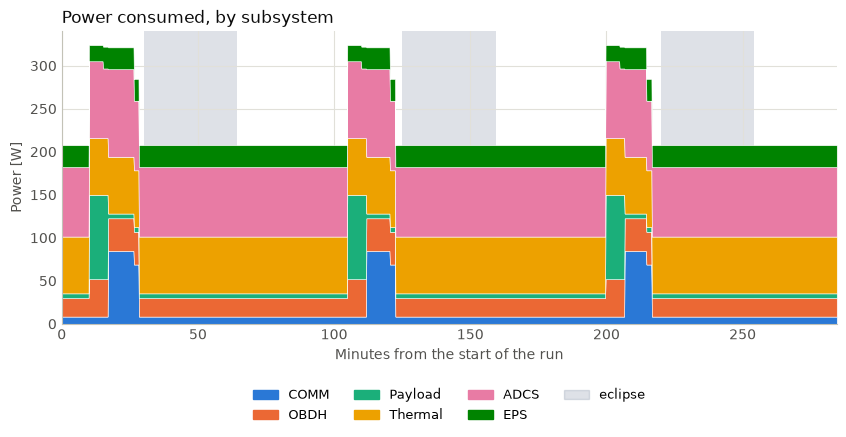

In [5]:
consumption_plot(loads)
plt.show()

## The loads per orbit

One row for each whole orbit, counted from the start of the run: the mean and the peak load, the energy drawn, and the part of it drawn in eclipse, which the battery must give.

In [6]:
loads.orbit_table.style.hide(axis="index").format(
    {
        "mean load [W]": "{:.1f}",
        "peak load [W]": "{:.1f}",
        "energy [Wh]": "{:.1f}",
        "in eclipse [Wh]": "{:.1f}",
    }
)

orbit,start [UTC],mean load [W],peak load [W],energy [Wh],in eclipse [Wh]
1,2026-10-01T09:00:00.000,228.9,323.9,361.9,118.7
2,2026-10-01T10:34:51.055,228.0,323.9,360.4,118.7
3,2026-10-01T12:09:42.109,227.2,323.9,359.2,118.7


## Changing the loads

Edit the two consumption files and run the notebook again from the top. The notebook never writes them.

For example, give the reaction wheels 25 W a unit in the platform's `slew`, for the torque of the turns. Each slew then draws 60 W more than idle, with the margin on top.

Or add a mode, such as `safe`, as a column of either file. It is noted as unused until an activity in the scenario gives its group that mode.

The power budget, `power_budget.ipynb`, sets these loads against the generation and the battery.